Install and Import Dependencies


In [ ]:
# Install required packages
!pip install yfinance pandas numpy scipy matplotlib seaborn pandas-datareader --quiet

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import pandas_datareader as pdr
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from scipy.optimize import minimize
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams.update({
    'figure.facecolor': '#0f0f23',
    'axes.facecolor':   '#1a1a2e',
    'axes.edgecolor':   '#444466',
    'axes.labelcolor':  '#ccccee',
    'xtick.color':      '#ccccee',
    'ytick.color':      '#ccccee',
    'text.color':       '#ccccee',
    'grid.color':       '#333355',
    'grid.linestyle':   '--',
    'grid.alpha':       0.5,
    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
})

print("✅ All libraries loaded successfully.")

✅ All libraries loaded successfully.


Define Your Portfolio

In [ ]:
# ============================================================
#   ✏️  USER INPUT — Edit this cell
# ============================================================

# List of stock tickers (Yahoo Finance format)
TICKERS = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA']

# Corresponding weights for your CURRENT portfolio (must sum to 1)
WEIGHTS = [0.30, 0.25, 0.20, 0.15, 0.10]

# Date range for historical data
START_DATE = '2020-01-01'
END_DATE   = '2024-12-31'

# Number of portfolios to simulate for the frontier
NUM_PORTFOLIOS = 5000

# Risk-free rate (annualised, e.g. 0.05 = 5%)
RISK_FREE_RATE = 0.05

# ============================================================

assert abs(sum(WEIGHTS) - 1.0) < 1e-6, "❌ Weights must sum to 1.0"
assert len(TICKERS) == len(WEIGHTS),    "❌ Number of tickers must match number of weights"

WEIGHTS = np.array(WEIGHTS)
print(f"✅ Portfolio defined: {dict(zip(TICKERS, WEIGHTS))}")
print(f"   Date range : {START_DATE} → {END_DATE}")
print(f"   Risk-free  : {RISK_FREE_RATE*100:.2f}%")

✅ Portfolio defined: {'AAPL': np.float64(0.3), 'MSFT': np.float64(0.25), 'GOOGL': np.float64(0.2), 'AMZN': np.float64(0.15), 'TSLA': np.float64(0.1)}
   Date range : 2020-01-01 → 2024-12-31
   Risk-free  : 5.00%


Fetch Price Data from Yahoo Finance

In [ ]:
print("📡 Fetching adjusted close prices from Yahoo Finance...")

raw = yf.download(TICKERS, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

# Handle both single and multi-ticker DataFrames
if isinstance(raw.columns, pd.MultiIndex):
    prices = raw['Close'][TICKERS].dropna()
else:
    prices = raw[['Close']].dropna()
    prices.columns = TICKERS

print(f"✅ Downloaded {len(prices)} trading days for {len(TICKERS)} stocks.")
print(f"   Period: {prices.index[0].date()} → {prices.index[-1].date()}")
prices.tail()

📡 Fetching adjusted close prices from Yahoo Finance...
✅ Downloaded 1257 trading days for 5 stocks.
   Period: 2020-01-02 → 2024-12-30


Ticker,AAPL,MSFT,GOOGL,AMZN,TSLA
Date,,,,,
2024-12-23,253.883133,431.078857,193.734344,225.059998,430.600006
2024-12-24,256.797211,435.119720,195.207535,229.050003,462.279999
2024-12-26,257.612701,433.911438,194.699890,227.050003,454.130005
2024-12-27,254.201370,426.404083,191.872925,223.750000,431.660004
2024-12-30,250.829788,420.758698,190.359940,221.300003,417.410004


Compute Daily Log Returns

📊 Daily Log Returns (first 5 rows):


Ticker,AAPL,MSFT,GOOGL,AMZN,TSLA
Date,,,,,
2020-01-03,-0.009770,-0.012530,-0.005245,-0.012213,0.029203
2020-01-06,0.007937,0.002581,0.026305,0.014776,0.019072
2020-01-07,-0.004714,-0.009159,-0.001933,0.002089,0.038067
2020-01-08,0.015958,0.015803,0.007093,-0.007839,0.048033
2020-01-09,0.021018,0.012415,0.010443,0.004788,-0.022189


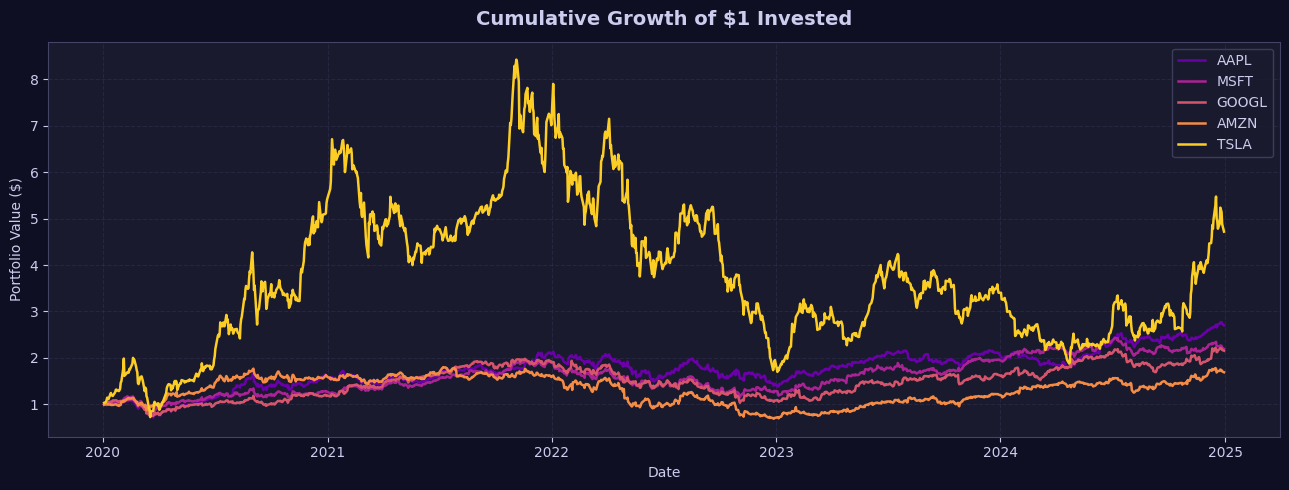

In [ ]:
# Daily log return = ln(P_t / P_{t-1})
log_returns = np.log(prices / prices.shift(1)).dropna()

print("📊 Daily Log Returns (first 5 rows):")
display(log_returns.head())

# --- Visualise cumulative returns ---
fig, ax = plt.subplots(figsize=(13, 5))
cumulative = (log_returns + 1).cumprod()
colors = cm.plasma(np.linspace(0.2, 0.9, len(TICKERS)))
for i, ticker in enumerate(TICKERS):
    ax.plot(cumulative.index, cumulative[ticker], label=ticker, color=colors[i], linewidth=1.8)
ax.set_title('Cumulative Growth of $1 Invested', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Date')
ax.set_ylabel('Portfolio Value ($)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

Expected Returns, Volatility & Correlation


📋 Individual Stock Statistics:


,Expected Return (Ann.),Volatility (Ann.),Sharpe Ratio
Ticker,,,
AAPL,24.93%,31.66%,0.629
MSFT,20.41%,30.53%,0.505
GOOGL,20.69%,32.53%,0.482
AMZN,16.99%,35.97%,0.333
TSLA,53.73%,67.01%,0.727


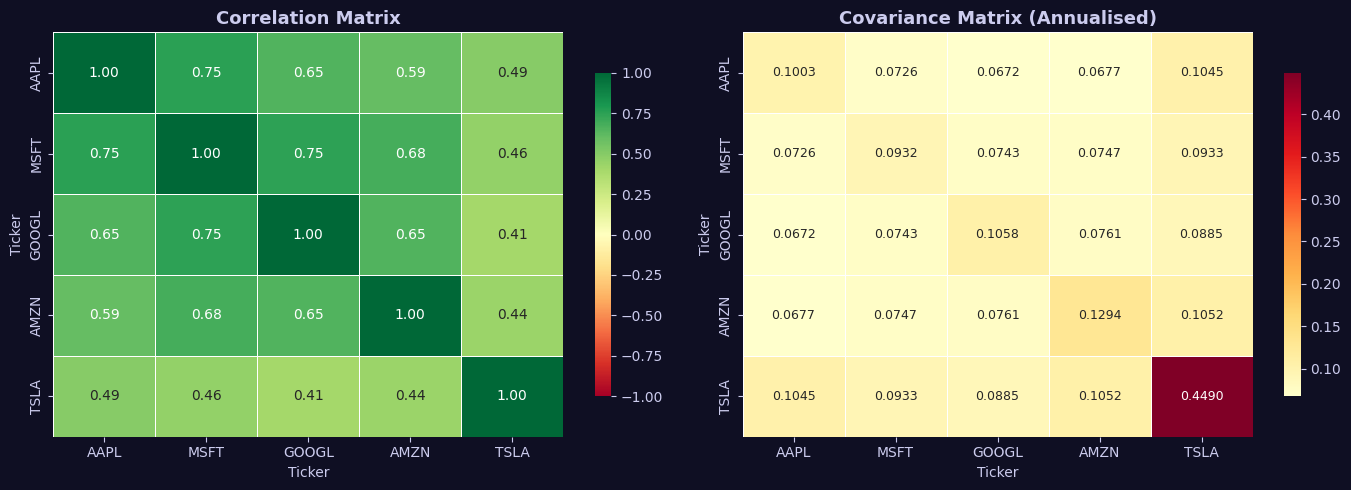


📐 Annualised Covariance Matrix:


Ticker,AAPL,MSFT,GOOGL,AMZN,TSLA
Ticker,,,,,
AAPL,0.100265,0.072596,0.067248,0.067739,0.104471
MSFT,0.072596,0.093226,0.074289,0.074698,0.093285
GOOGL,0.067248,0.074289,0.105840,0.076055,0.088513
AMZN,0.067739,0.074698,0.076055,0.129389,0.105196
TSLA,0.104471,0.093285,0.088513,0.105196,0.448998


In [ ]:
TRADING_DAYS = 252

# Annualised expected return = mean(daily log returns) × 252
expected_returns = log_returns.mean() * TRADING_DAYS

# Annualised volatility = std(daily log returns) × sqrt(252)
volatility = log_returns.std() * np.sqrt(TRADING_DAYS)

# Correlation matrix
correlation_matrix = log_returns.corr()

# Annualised covariance matrix
cov_matrix = log_returns.cov() * TRADING_DAYS

# Summary table
summary = pd.DataFrame({
    'Expected Return (Ann.)': expected_returns.map('{:.2%}'.format),
    'Volatility (Ann.)':      volatility.map('{:.2%}'.format),
    'Sharpe Ratio':           ((expected_returns - RISK_FREE_RATE) / volatility).map('{:.3f}'.format)
})
print("\n📋 Individual Stock Statistics:")
display(summary)

# --- Heatmap: Correlation Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            linewidths=0.5, ax=axes[0], vmin=-1, vmax=1,
            annot_kws={'size': 10},
            cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlation Matrix', fontsize=13, fontweight='bold')
axes[0].tick_params(colors='#ccccee')

sns.heatmap(cov_matrix, annot=True, fmt='.4f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[1],
            annot_kws={'size': 9},
            cbar_kws={'shrink': 0.8})
axes[1].set_title('Covariance Matrix (Annualised)', fontsize=13, fontweight='bold')
axes[1].tick_params(colors='#ccccee')

plt.tight_layout()
plt.show()

print("\n📐 Annualised Covariance Matrix:")
display(cov_matrix.style.format('{:.6f}'))

Current Portfolio Metrics

In [ ]:
def portfolio_performance(weights, expected_returns, cov_matrix):
    """Return (annualised_return, annualised_volatility, sharpe_ratio)"""
    ret  = np.dot(weights, expected_returns)
    vol  = np.sqrt(weights @ cov_matrix.values @ weights)
    sharpe = (ret - RISK_FREE_RATE) / vol
    return ret, vol, sharpe

port_ret, port_vol, port_sharpe = portfolio_performance(WEIGHTS, expected_returns, cov_matrix)

print("="*50)
print("  📦 CURRENT PORTFOLIO METRICS")
print("="*50)
for ticker, w in zip(TICKERS, WEIGHTS):
    print(f"   {ticker:8s}  {w*100:5.1f}%")
print("-"*50)
print(f"   Expected Return  : {port_ret:.2%}")
print(f"   Volatility (Risk): {port_vol:.2%}")
print(f"   Sharpe Ratio     : {port_sharpe:.4f}")
print("="*50)

  📦 CURRENT PORTFOLIO METRICS
   AAPL       30.0%
   MSFT       25.0%
   GOOGL      20.0%
   AMZN       15.0%
   TSLA       10.0%
--------------------------------------------------
   Expected Return  : 24.64%
   Volatility (Risk): 29.46%
   Sharpe Ratio     : 0.6668


Monte Carlo Simulation

In [ ]:
np.random.seed(42)
n = len(TICKERS)

sim_returns  = np.zeros(NUM_PORTFOLIOS)
sim_vols     = np.zeros(NUM_PORTFOLIOS)
sim_sharpes  = np.zeros(NUM_PORTFOLIOS)
sim_weights  = np.zeros((NUM_PORTFOLIOS, n))

for i in range(NUM_PORTFOLIOS):
    w = np.random.dirichlet(np.ones(n))  # random weights summing to 1
    r, v, s = portfolio_performance(w, expected_returns, cov_matrix)
    sim_returns[i]   = r
    sim_vols[i]      = v
    sim_sharpes[i]   = s
    sim_weights[i]   = w

print(f"✅ Simulated {NUM_PORTFOLIOS:,} random portfolios.")
print(f"   Return range : {sim_returns.min():.2%}  →  {sim_returns.max():.2%}")
print(f"   Risk   range : {sim_vols.min():.2%}  →  {sim_vols.max():.2%}")
print(f"   Best Sharpe  : {sim_sharpes.max():.4f}")

✅ Simulated 5,000 random portfolios.
   Return range : 17.96%  →  49.58%
   Risk   range : 28.30%  →  60.61%
   Best Sharpe  : 0.7891


SLSQP Optimisation

In [ ]:
def neg_sharpe(weights):
    r, v, _ = portfolio_performance(weights, expected_returns, cov_matrix)
    return -(r - RISK_FREE_RATE) / v   # minimise negative Sharpe = maximise Sharpe

def portfolio_volatility(weights):
    return portfolio_performance(weights, expected_returns, cov_matrix)[1]

def portfolio_return(weights):
    return portfolio_performance(weights, expected_returns, cov_matrix)[0]

constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]   # weights sum to 1
bounds      = tuple((0.0, 1.0) for _ in range(n))                 # no short-selling
w0          = np.array([1.0 / n] * n)                             # equal-weight starting point

# ── A. Maximum Sharpe Portfolio ──────────────────────────────
res_sharpe = minimize(neg_sharpe, w0,
                      method='SLSQP', bounds=bounds, constraints=constraints,
                      options={'maxiter': 1000, 'ftol': 1e-9})
w_max_sharpe   = res_sharpe.x
r_ms, v_ms, s_ms = portfolio_performance(w_max_sharpe, expected_returns, cov_matrix)

# ── B. Minimum Variance Portfolio ───────────────────────────
res_minvar = minimize(portfolio_volatility, w0,
                      method='SLSQP', bounds=bounds, constraints=constraints,
                      options={'maxiter': 1000, 'ftol': 1e-9})
w_min_var      = res_minvar.x
r_mv, v_mv, s_mv = portfolio_performance(w_min_var, expected_returns, cov_matrix)

# ── C. Efficient Frontier (sweep target returns) ────────────
target_rets = np.linspace(sim_returns.min(), sim_returns.max(), 200)
ef_vols, ef_rets = [], []

for target in target_rets:
    cons = [
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
        {'type': 'eq', 'fun': lambda w, t=target: portfolio_return(w) - t}
    ]
    res = minimize(portfolio_volatility, w0,
                   method='SLSQP', bounds=bounds, constraints=cons,
                   options={'maxiter': 500, 'ftol': 1e-9})
    if res.success:
        ef_vols.append(res.fun)
        ef_rets.append(target)

ef_vols = np.array(ef_vols)
ef_rets = np.array(ef_rets)

print(f"✅ Efficient Frontier computed with {len(ef_rets)} points.")
print()
print("📌 Maximum Sharpe Ratio Portfolio:")
print(f"   Return: {r_ms:.2%} | Volatility: {v_ms:.2%} | Sharpe: {s_ms:.4f}")
print(f"   Weights: {dict(zip(TICKERS, np.round(w_max_sharpe, 4)))}")
print()
print("📌 Minimum Variance Portfolio:")
print(f"   Return: {r_mv:.2%} | Volatility: {v_mv:.2%} | Sharpe: {s_mv:.4f}")
print(f"   Weights: {dict(zip(TICKERS, np.round(w_min_var, 4)))}")

✅ Efficient Frontier computed with 200 points.

📌 Maximum Sharpe Ratio Portfolio:
   Return: 36.38% | Volatility: 39.63% | Sharpe: 0.7919
   Weights: {'AAPL': np.float64(0.5246), 'MSFT': np.float64(0.0), 'GOOGL': np.float64(0.0677), 'AMZN': np.float64(0.0), 'TSLA': np.float64(0.4077)}

📌 Minimum Variance Portfolio:
   Return: 21.51% | Volatility: 28.23% | Sharpe: 0.5848
   Weights: {'AAPL': np.float64(0.3246), 'MSFT': np.float64(0.3118), 'GOOGL': np.float64(0.2367), 'AMZN': np.float64(0.1268), 'TSLA': np.float64(0.0)}


Efficient Frontier Chart & Portfolio Deviation

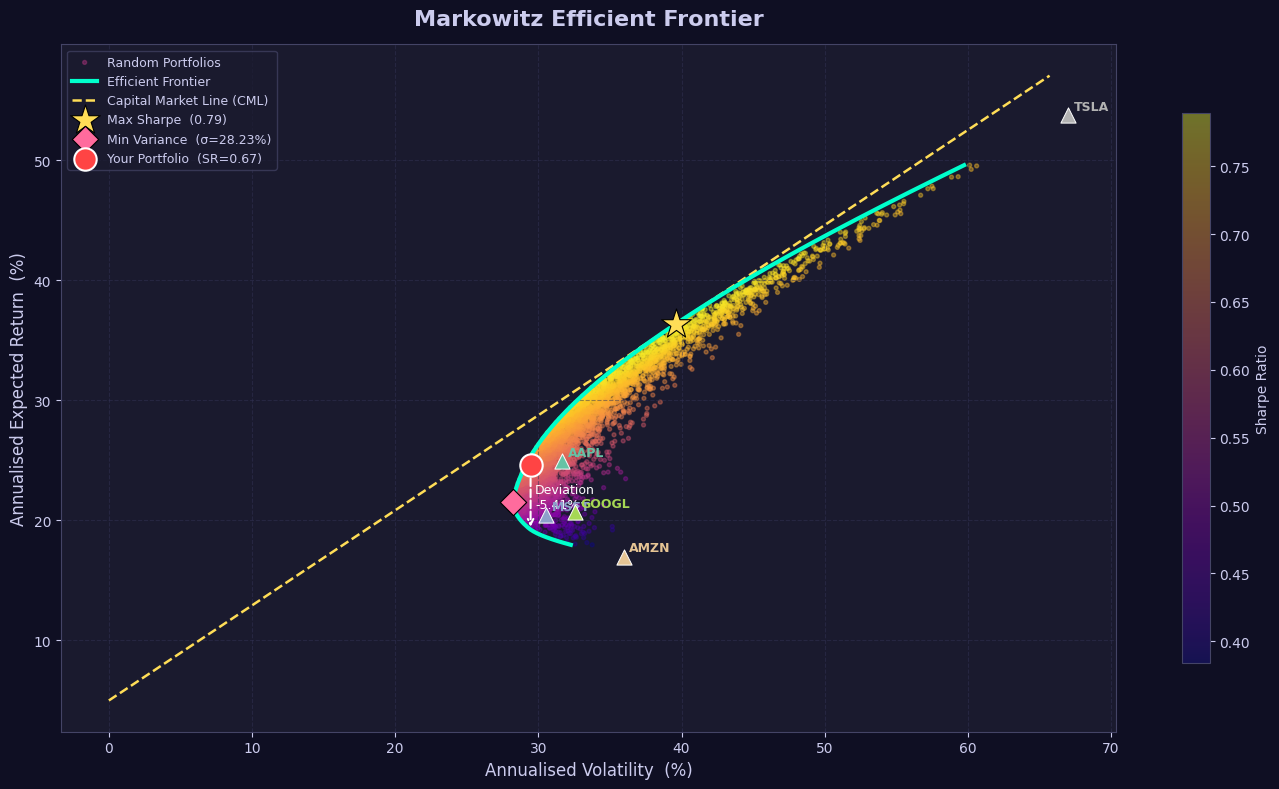

💾 Chart saved as 'efficient_frontier.png'


In [ ]:

fig, ax = plt.subplots(figsize=(14, 8))

# Simulated portfolios coloured by Sharpe ratio
scatter = ax.scatter(sim_vols * 100, sim_returns * 100,
                     c=sim_sharpes, cmap='plasma',
                     alpha=0.4, s=8, label='Random Portfolios')
plt.colorbar(scatter, ax=ax, label='Sharpe Ratio', shrink=0.8)

# Efficient Frontier
ax.plot(ef_vols * 100, ef_rets * 100,
        color='#00ffcc', linewidth=3, zorder=5, label='Efficient Frontier')

# Capital Market Line (CML)
cml_x = np.linspace(0, ef_vols.max() * 100 * 1.1, 300)
cml_y = RISK_FREE_RATE * 100 + s_ms * cml_x
ax.plot(cml_x, cml_y, '--', color='#ffdd57', linewidth=1.8,
        label='Capital Market Line (CML)', zorder=4)

# Maximum Sharpe Portfolio ★
ax.scatter(v_ms * 100, r_ms * 100, marker='*', s=500,
           color='#ffdd57', zorder=10, label=f'Max Sharpe  ({s_ms:.2f})',
           edgecolors='black', linewidths=0.8)

# Minimum Variance Portfolio ◆
ax.scatter(v_mv * 100, r_mv * 100, marker='D', s=180,
           color='#ff6b9d', zorder=10, label=f'Min Variance  (σ={v_mv:.2%})',
           edgecolors='black', linewidths=0.8)

# Your Portfolio ●
ax.scatter(port_vol * 100, port_ret * 100, marker='o', s=260,
           color='#ff4444', zorder=10, label=f'Your Portfolio  (SR={port_sharpe:.2f})',
           edgecolors='white', linewidths=1.5)

# Annotation: deviation arrow
# Find the efficient frontier point at the same volatility
ef_df = pd.DataFrame({'vol': ef_vols, 'ret': ef_rets})
closest_idx = (ef_df['vol'] - port_vol).abs().idxmin()
ef_ret_at_port_vol = ef_df.loc[closest_idx, 'ret']
deviation = ef_ret_at_port_vol - port_ret

ax.annotate('',
            xy =(port_vol * 100, ef_ret_at_port_vol * 100),
            xytext=(port_vol * 100, port_ret * 100),
            arrowprops=dict(arrowstyle='->', color='white', lw=1.5, linestyle='dashed'))
ax.text(port_vol * 100 + 0.3, (port_ret + deviation / 2) * 100,
        f'Deviation\n{deviation:.2%}',
        color='white', fontsize=9, va='center')

# Individual stocks
colors_ind = cm.Set2(np.linspace(0, 1, n))
for i, ticker in enumerate(TICKERS):
    ax.scatter(volatility[ticker] * 100, expected_returns[ticker] * 100,
               marker='^', s=120, color=colors_ind[i], zorder=9,
               edgecolors='white', linewidths=0.7)
    ax.annotate(ticker,
                xy=(volatility[ticker] * 100, expected_returns[ticker] * 100),
                xytext=(4, 4), textcoords='offset points',
                fontsize=9, color=colors_ind[i], fontweight='bold')

ax.set_xlabel('Annualised Volatility  (%)', fontsize=12)
ax.set_ylabel('Annualised Expected Return  (%)', fontsize=12)
ax.set_title('Markowitz Efficient Frontier', fontsize=16, fontweight='bold', pad=14)
ax.legend(loc='upper left', fontsize=9, framealpha=0.7)
ax.grid(True)
plt.tight_layout()
plt.savefig('efficient_frontier.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("💾 Chart saved as 'efficient_frontier.png'")

Portfolio Comparison Summary

In [ ]:
def weights_dict(w):
    return {t: f"{v:.2%}" for t, v in zip(TICKERS, w)}

summary_df = pd.DataFrame([
    {
        'Portfolio'         : 'Your Current Portfolio',
        'Ann. Return'       : f"{port_ret:.2%}",
        'Ann. Volatility'   : f"{port_vol:.2%}",
        'Sharpe Ratio'      : f"{port_sharpe:.4f}",
        **weights_dict(WEIGHTS)
    },
    {
        'Portfolio'         : '★ Max Sharpe Portfolio',
        'Ann. Return'       : f"{r_ms:.2%}",
        'Ann. Volatility'   : f"{v_ms:.2%}",
        'Sharpe Ratio'      : f"{s_ms:.4f}",
        **weights_dict(w_max_sharpe)
    },
    {
        'Portfolio'         : '◆ Min Variance Portfolio',
        'Ann. Return'       : f"{r_mv:.2%}",
        'Ann. Volatility'   : f"{v_mv:.2%}",
        'Sharpe Ratio'      : f"{s_mv:.4f}",
        **weights_dict(w_min_var)
    },
]).set_index('Portfolio')

print("\n📊 Portfolio Comparison:")
display(summary_df)

print(f"\n🔍 Deviation from Efficient Frontier:")
print(f"   At your portfolio's risk level ({port_vol:.2%} volatility),")
print(f"   the Efficient Frontier offers {ef_ret_at_port_vol:.2%} expected return.")
print(f"   Your portfolio returns {port_ret:.2%} — a deviation of {deviation:.2%}.")
if deviation > 0:
    print("   ✅ Your portfolio is ABOVE the simulated frontier (excellent!). Verify data quality.")
elif deviation < -0.01:
    print(f"   ⚠️  Rebalancing towards the Efficient Frontier could improve returns by ~{abs(deviation):.2%}.")
else:
    print("   ✅ Your portfolio is close to the Efficient Frontier. Well positioned!")


📊 Portfolio Comparison:


,Ann. Return,Ann. Volatility,Sharpe Ratio,AAPL,MSFT,GOOGL,AMZN,TSLA
Portfolio,,,,,,,,
Your Current Portfolio,24.64%,29.46%,0.6668,30.00%,25.00%,20.00%,15.00%,10.00%
★ Max Sharpe Portfolio,36.38%,39.63%,0.7919,52.46%,0.00%,6.77%,0.00%,40.77%
◆ Min Variance Portfolio,21.51%,28.23%,0.5848,32.46%,31.18%,23.67%,12.68%,0.00%



🔍 Deviation from Efficient Frontier:
   At your portfolio's risk level (29.46% volatility),
   the Efficient Frontier offers 19.23% expected return.
   Your portfolio returns 24.64% — a deviation of -5.41%.
   ⚠️  Rebalancing towards the Efficient Frontier could improve returns by ~5.41%.


Weight Allocation Chart

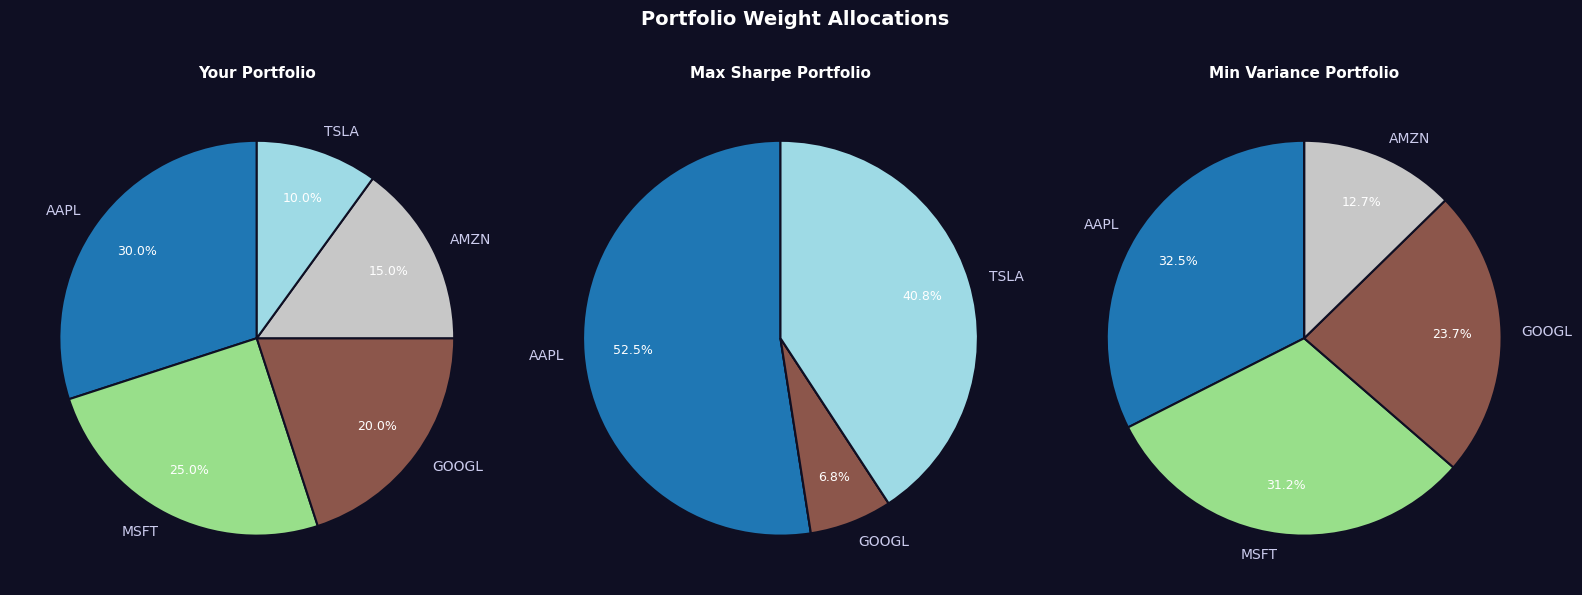

💾 Chart saved as 'portfolio_weights.png'


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
portfolios = [
    ('Your Portfolio',          WEIGHTS,        '#ff4444'),
    ('Max Sharpe Portfolio',    w_max_sharpe,   '#ffdd57'),
    ('Min Variance Portfolio',  w_min_var,      '#ff6b9d'),
]

for ax, (title, w, colour) in zip(axes, portfolios):
    threshold = 0.01
    labels = [t if wt > threshold else '' for t, wt in zip(TICKERS, w)]
    wedge_colors = cm.tab20(np.linspace(0, 1, len(TICKERS)))
    wedges, texts, autotexts = ax.pie(
        w, labels=labels, autopct=lambda p: f'{p:.1f}%' if p > 1 else '',
        colors=wedge_colors, pctdistance=0.75,
        wedgeprops={'edgecolor': '#0f0f23', 'linewidth': 1.5},
        startangle=90
    )
    for at in autotexts:
        at.set_color('white')
        at.set_fontsize(9)
    ax.set_title(title, fontsize=11, fontweight='bold', color='white', pad=10)

plt.suptitle('Portfolio Weight Allocations', fontsize=14, fontweight='bold', color='white', y=1.02)
plt.tight_layout()
plt.savefig('portfolio_weights.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("💾 Chart saved as 'portfolio_weights.png'")

Rolling Risk & Return Analysis

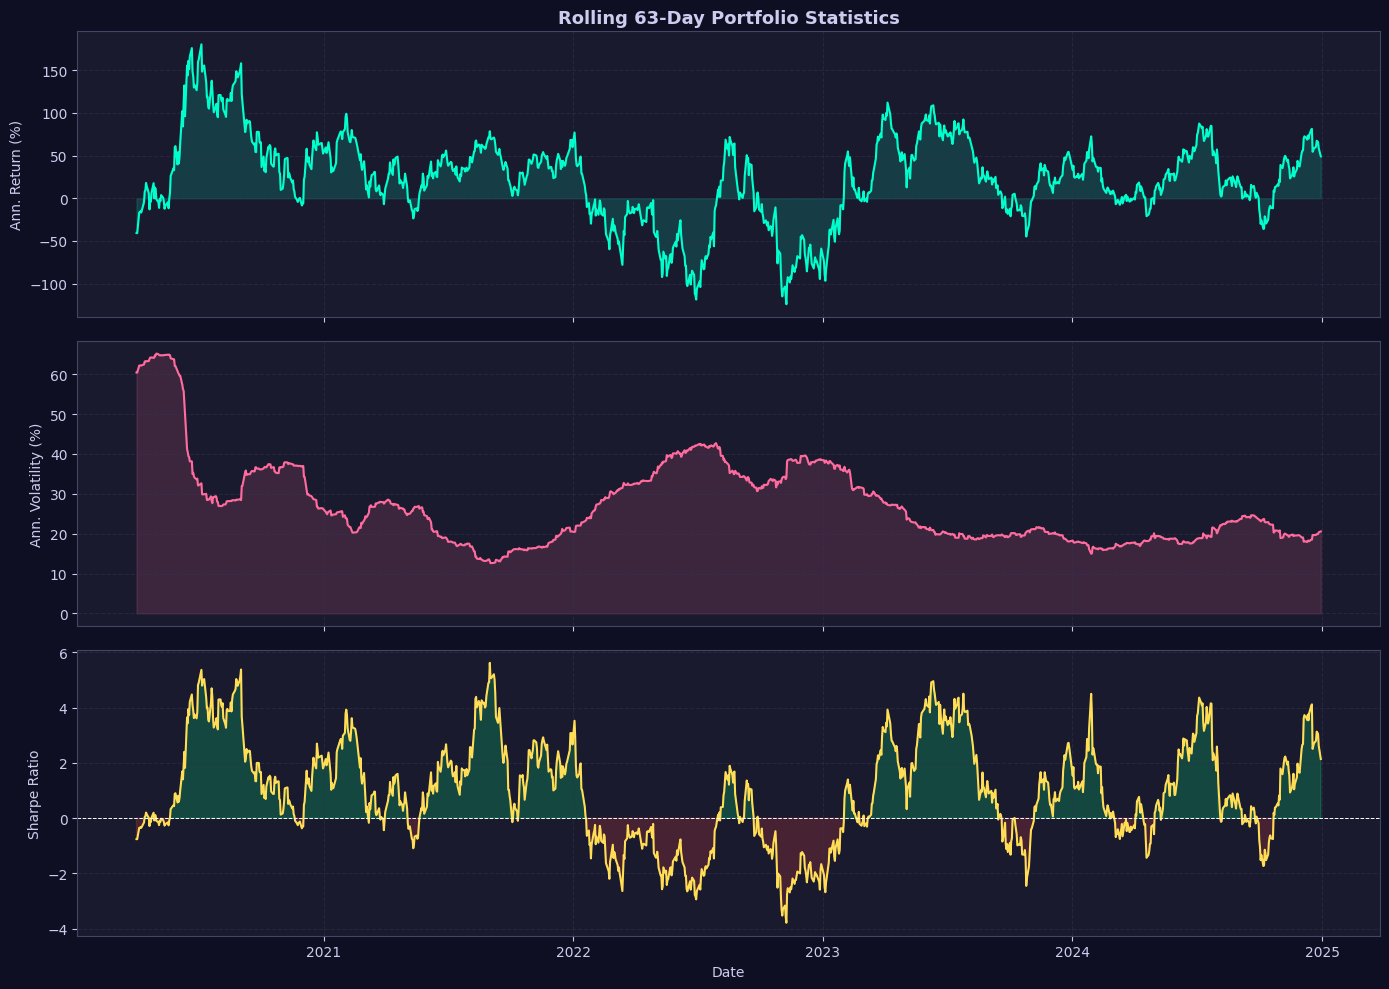

💾 Chart saved as 'rolling_analysis.png'


In [ ]:
# Weighted portfolio daily return
port_daily = log_returns @ WEIGHTS
WINDOW = 63  # ~1 quarter

rolling_ret = port_daily.rolling(WINDOW).mean() * TRADING_DAYS
rolling_vol = port_daily.rolling(WINDOW).std()  * np.sqrt(TRADING_DAYS)
rolling_sharpe = (rolling_ret - RISK_FREE_RATE) / rolling_vol

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(rolling_ret.index, rolling_ret * 100, color='#00ffcc', linewidth=1.5)
axes[0].fill_between(rolling_ret.index, rolling_ret * 100, alpha=0.15, color='#00ffcc')
axes[0].set_ylabel('Ann. Return (%)')
axes[0].set_title(f'Rolling {WINDOW}-Day Portfolio Statistics', fontsize=13, fontweight='bold')
axes[0].grid(True)

axes[1].plot(rolling_vol.index, rolling_vol * 100, color='#ff6b9d', linewidth=1.5)
axes[1].fill_between(rolling_vol.index, rolling_vol * 100, alpha=0.15, color='#ff6b9d')
axes[1].set_ylabel('Ann. Volatility (%)')
axes[1].grid(True)

axes[2].plot(rolling_sharpe.index, rolling_sharpe, color='#ffdd57', linewidth=1.5)
axes[2].axhline(0, color='white', linewidth=0.7, linestyle='--')
axes[2].fill_between(rolling_sharpe.index, rolling_sharpe,
                     where=rolling_sharpe >= 0, alpha=0.2, color='#00ff88')
axes[2].fill_between(rolling_sharpe.index, rolling_sharpe,
                     where=rolling_sharpe < 0,  alpha=0.2, color='#ff4444')
axes[2].set_ylabel('Sharpe Ratio')
axes[2].set_xlabel('Date')
axes[2].grid(True)

plt.tight_layout()
plt.savefig('rolling_analysis.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("💾 Chart saved as 'rolling_analysis.png'")